# 8. Rotational Spectra of Methane

The rotational spectrum of methane, a nonlinear molecule, is computed by the phase-space sampling (see also section III B of the paper). 

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Quaternion (4 DOFs) with 1 constraint (norm) | none | `ImplicitVerlet` | Euler angles (3 DOFs) |

- **Rigid rotor**: The rotation is propagated directly by the quaternion, as in the *Direct Dynamics* tutorial.
Since the potential energy is constant for the rigid rotation, no potential is given, and no Hessian evaluation is needed.

- **Initial states**: Coherent states in the Euler angles centered at the reference orientation ($\psi, \theta, \phi$) = (0, $\pi / 2$, 0), with the rotational kinetic energies of 50, 200 and 500 $\textrm{cm}^{-1}$ and the widths of 0.2 rad.

- **Sampling**: As in the paper, the initial orientation is fixed at the center of the initial states, and only the angular momenta are sampled: the direction is uniform on the unit sphere, and the rotational kinetic energy is uniform.

- **Coordinate singularities**: The trajectories pass through the gimbal lock of the Euler angles ($\theta = 0, \pi$) depending on the direction of the angular momentum. The steps where the symplectic condition is not satisfied are excluded.

- **Reference**: Since methane is a spherical top molecule, the rotational levels are given analytically by $E_J = B J(J+1)$, the same formula as for a linear molecule.

In [1]:
# import necessary libraries

import time
 
import numpy as np
 
from pyscivr.basis import get_overlap
from pyscivr.coordinates import QuaternionCoordinates, quaternion_metric
from pyscivr.integrators import ImplicitVerlet
from pyscivr.scivr import get_action, get_lagrangian, get_prefactor, get_ta_spectrum_fft
from pyscivr.units import CmInv, FemtoSec, HBar
from pyscivr.utils import get_geom, get_inertia, get_mass_center
from pyscivr.variations import make_jacobi_func, make_vari_propagator_implicit, propagate_variation_implicit, to_internal

## System and coordinates

The system and the coordinates are the same as in the *Direct Dynamics* tutorial.

The reference structure must be centered at the origin and oriented along the principal axes, so that the moments of inertia can be passed to `quaternion_metric`.

`QuaternionCoordinates` defines the Euler angles (yaw, pitch and roll) and the norm condition of the quaternion, where the Euler angles are active. The Jacobian functions are made once and reused for all trajectories.


## Sampling of initial conditions

`angular_momentum` gives the angular momentum in the body frame with the rotational kinetic energy `K_rot` along the direction `L_dir`, where $K_{\text{rot}} = \frac{L^T I^{-1} L}{2}$.

`sample_momenta` samples the direction uniformly on the unit sphere and `K_rot` uniformly, and converts the angular momenta into the quaternion momenta by $p = 2 S(q)^T L_{\text{body}}$.

## Calculation of spectra

`run` computes the spectra for all the initial states by the following steps for each trajectory:

1. Propagate the trajectory by `ImplicitVerlet` with `normalize=True`.
2. Propagate the variation and compute the monodromy matrix in the Euler angles.
3. Exclude the steps where the symplectic condition is not satisfied.
4. Compute the action, the prefactor and the overlap with each initial state, and the spectrum by the FFT.

The spectra are averaged over the trajectories and saved for each initial state.
Note that each trajectory is used for all the initial states, so that the cost of the dynamics and the monodromy matrix is shared.

In [ ]:
# Constants
XYZSTR = """
C        -0.000000000000       0.000000000000      -0.000000000000
H         0.627615334142       0.627615334142       0.627615334142
H        -0.627615334142      -0.627615334142       0.627615334142
H         0.627615334142      -0.627615334142      -0.627615334142
H        -0.627615334142       0.627615334142      -0.627615334142
"""
SYMBOLS, POSI_REF, MASS = get_geom(XYZSTR)
assert np.allclose(get_mass_center(POSI_REF, MASS), 0.0) # centered at the origin
INERTIA_TENSOR = get_inertia(POSI_REF, MASS)
assert np.allclose(INERTIA_TENSOR, np.diag(np.diag(INERTIA_TENSOR))) # principal axis frame
INERTIA = np.diag(INERTIA_TENSOR) # (3,) principal moments of inertia

METRIC_FUNC = quaternion_metric(INERTIA)
Q_INIT = np.array([1.0, 0.0, 0.0, 0.0]) # reference orientation (no rotation)

# Coordinates (Euler angles and the norm condition)
COORD_ALL = QuaternionCoordinates()
ACTIVE_IDX = np.array([0, 1, 2]) # yaw, pitch, roll
TOPOLOGIES = [COORD_ALL.topology[i] for i in ACTIVE_IDX] # S1, I-, S1

JACOBI_FUNC, JACOBI_REV_FUNC, INTERNAL_FUNC, MONODROMY_FUNC = make_jacobi_func(COORD_ALL, ACTIVE_IDX)


def get_S(q):
    """omega_body = 2 S(q) dq/dt, p = 2 S(q)^T L_body, L_body = S(q) p / 2 (|q| = 1)."""
    q0, q1, q2, q3 = q
    return np.array([[-q1, q0, q3, -q2],
                     [-q2, -q3, q0, q1],
                     [-q3, q2, -q1, q0]])


def angular_momentum(K_rot, L_dir):
    """Angular momentum in the body frame with the rotational kinetic energy K_rot [cm^-1] along L_dir."""
    L_dir = np.atleast_2d(L_dir)
    return np.sqrt(2.0 * np.atleast_1d(K_rot)[:, None] * CmInv / np.sum(L_dir**2 / INERTIA, axis=1, keepdims=True)) * L_dir


def sample_momenta(n_sample, K_rot_range, seed=10202):
    rng = np.random.default_rng(seed)
    L_dir = rng.normal(size=(n_sample, 3))
    L_dir /= np.linalg.norm(L_dir, axis=1, keepdims=True) # uniform on the unit sphere
    K_rot = rng.uniform(*K_rot_range, size=n_sample)
    mome = 2.0 * angular_momentum(K_rot, L_dir) @ get_S(Q_INIT) # (n_sample, 4)
    return mome, K_rot


def run(mome_sample_list, K_rot_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft, symp_err_tol=1e-2):

    # Judge function to check if the point is singular or not
    judge_func = lambda symp_err: np.isfinite(symp_err) & (symp_err < symp_err_tol)

    # Reference positions and momenta in the Euler angles
    posi_ref_int, mome_ref_int = zip(*[INTERNAL_FUNC(Q_INIT, p) for p in mome_ref_list])

    n_sample = len(mome_sample_list)
    n_ref = len(mome_ref_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator_implicit(METRIC_FUNC, dt, normalize=True)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        traj = ImplicitVerlet(Q_INIT, mome_sample_list[i], dt, METRIC_FUNC, normalize=True).run(n_step)
        posi, mome = traj["posi"], traj["mome"]

        # Get variation
        J_rev_init = JACOBI_REV_FUNC(posi[0], mome[0])
        vari = propagate_variation_implicit(vari_propagator, posi, mome, traj["mome_half"], J_rev_init)
        posi_int, mome_int, mono_int, symplectic_error = to_internal(MONODROMY_FUNC, posi, mome, vari)

        # Points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"])   # V = 0
        action = get_action(lag, dt)

        for j in range(n_ref):
            gamma = gamma_ref_list[j]
            prefactor = get_prefactor(mono_int, gamma, valid=valid)
            overlap = get_overlap(TOPOLOGIES, posi_ref_int[j], mome_ref_int[j], posi_int, mome_int, gamma)
            ener_grid, spec = get_ta_spectrum_fft(prefactor, overlap, action, dt, n_fft, valid=valid)
            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, K_rot = {K_rot_list[i]:.1f}, "
                  f"max symp error = {np.max(symplectic_error):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j])

## Execute calculation

The total propagation time is 2000 fs.

A time step of 1 fs is sufficient for the slow rotation of methane.

In [3]:
if __name__ == "__main__":
    # set parameters
    n_sample = 2000
    dt = 1.0 * FemtoSec
    n_step = 2000
    n_fft = 2**19
 
    # set reference states
    K_rot_ref_list = [50.0, 200.0, 500.0]
    L_dir_ref = np.array([1.0, -1.0, -1.0])
    mome_ref_list = [2.0 * angular_momentum(k_rot, L_dir_ref)[0] @ get_S(Q_INIT) for k_rot in K_rot_ref_list]
 
    gamma_ref = [1.0 / (2 * 0.2**2)] * 3   # sqrt(1 / 2 gamma) = 0.2 rad for yaw, pitch, roll
    gamma_ref_list = np.asarray([gamma_ref] * len(K_rot_ref_list))
    fpath_list = [f"methane_pure_rot_{k_rot:.0f}_n_{n_sample}_spectra.npz" for k_rot in K_rot_ref_list]
 
    # sample the initial momenta
    mome_sample_list, K_rot_list = sample_momenta(n_sample, K_rot_range=(10.0, 1000.0))
 
    run(mome_sample_list, K_rot_list, mome_ref_list, gamma_ref_list, fpath_list, dt, n_step, n_fft)

     1 / 2000, K_rot = 439.3, max symp error = 5.819e-13, (1.1 sec)
    11 / 2000, K_rot = 67.9, max symp error = 5.046e-13, (1.9 sec)
    21 / 2000, K_rot = 336.4, max symp error = 9.443e-13, (2.6 sec)
    31 / 2000, K_rot = 739.7, max symp error = 1.821e-12, (3.3 sec)
    41 / 2000, K_rot = 307.7, max symp error = 1.533e-12, (4.0 sec)
    51 / 2000, K_rot = 890.7, max symp error = 1.272e-12, (4.7 sec)
    61 / 2000, K_rot = 367.5, max symp error = 7.165e-13, (5.4 sec)
    71 / 2000, K_rot = 590.6, max symp error = 8.061e-13, (6.1 sec)
    81 / 2000, K_rot = 822.9, max symp error = 8.603e-13, (6.8 sec)
    91 / 2000, K_rot = 676.4, max symp error = 1.498e-12, (7.5 sec)
   101 / 2000, K_rot = 964.9, max symp error = 1.716e-12, (8.2 sec)
   111 / 2000, K_rot = 46.4, max symp error = 2.675e-13, (8.9 sec)
   121 / 2000, K_rot = 169.4, max symp error = 1.049e-12, (9.6 sec)
   131 / 2000, K_rot = 216.6, max symp error = 9.727e-13, (10.3 sec)
   141 / 2000, K_rot = 889.7, max symp error = 2.

## Plot results

Since methane is a spherical top with the moment of inertia $I$, the rotational levels are given analytically by $E_J = B J(J+1)$ with $B = \frac{\hbar^2}{2I}$.

Rotational constant B = 5.307 cm^-1
Analytical rotational energies (cm^-1): [  0.   10.6  31.8  63.7 106.1 159.2 222.9 297.2 382.1 477.6 583.8 700.5
 827.9 965.9]
Peaks (cm^-1) for K = 50: [ 30.7  63.3 104.7 158.5 220.6 295.4]
Peaks (cm^-1) for K = 200: [ 30.5  62.5 104.5 158.  219.8 294.3 382.2 475.6 581.6]
Peaks (cm^-1) for K = 500: [104.6 157.1 219.4 293.5 381.6 475.3 580.9 697.9 826.6 965.7]


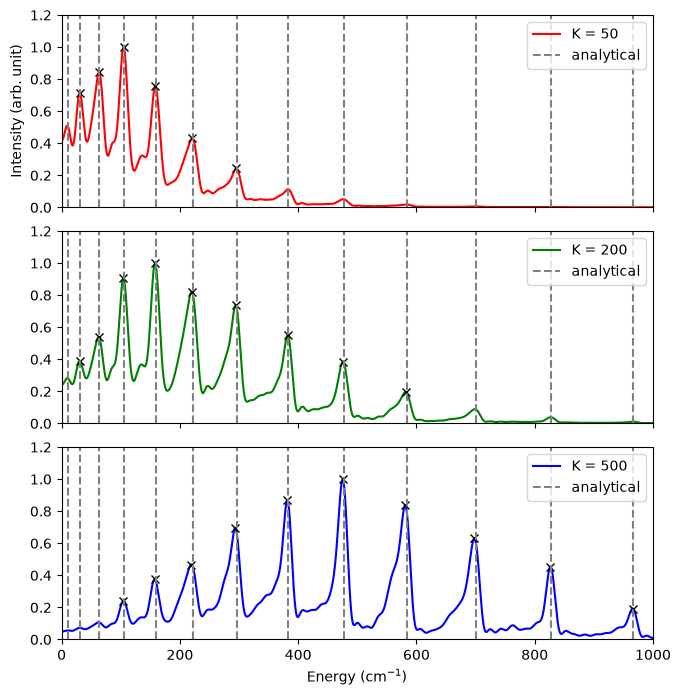

In [7]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks
 
    B = HBar**2 / (2.0 * INERTIA[0]) / CmInv
    analytical_energies = np.array([B * J * (J + 1) for J in range(20)])
    analytical_energies = analytical_energies[analytical_energies <= 1000]
    print(f"Rotational constant B = {B:.3f} cm^-1")
    print(f"Analytical rotational energies (cm^-1): {np.round(analytical_energies, 1)}")
 
    fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
    colors = ["red", "green", "blue"]

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum[ener_grid <= 1000])
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        peaks = peaks[ener_grid[peaks] <= 1000]
        print(f"Peaks (cm^-1) for K = {K_rot_ref_list[i]:.0f}: {np.round(ener_grid[peaks], 1)}")
 
        ax[i].plot(ener_grid, spectrum, label=f"K = {K_rot_ref_list[i]:.0f}", color=colors[i])
        ax[i].plot(ener_grid[peaks], spectrum[peaks], "x", color="black")
        ax[i].vlines(analytical_energies, 0.0, 1.2, color="gray", linestyle="--", label="analytical")
        ax[i].set_ylim(0, 1.2)
        ax[i].legend()
 
    ax[-1].set_xlim(0, 1000)
    ax[-1].set_xlabel("Energy (cm$^{-1}$)")
    ax[0].set_ylabel("Intensity (arb. unit)")
    plt.tight_layout()
    plt.show()

The computed peak positions for $K = 500$ $\textrm{cm}^{-1}$ are compared with the analytical eigenenergies
$E_J = B J(J+1)$ with $B = 5.307$ $\textrm{cm}^{-1}$ (all in $\textrm{cm}^{-1}$).

| $J$ | Computed | $B J(J+1)$ | Deviation |
|---|---|---|---|
| 4 | 104.6 | 106.1 | −1.5 |
| 5 | 157.1 | 159.2 | −2.1 |
| 6 | 219.4 | 222.9 | −3.5 |
| 7 | 293.5 | 297.2 | −3.7 |
| 8 | 381.6 | 382.1 | −0.5 |
| 9 | 475.3 | 477.6 | −2.3 |
| 10 | 580.9 | 583.8 | −2.9 |
| 11 | 697.9 | 700.5 | −2.6 |
| 12 | 826.6 | 827.9 | −1.3 |
| 13 | 965.7 | 965.9 | −0.2 |

- **Quantitative agreement**: The computed peaks agree with the analytical eigenenergies with an RMSE of about
2.3 $\textrm{cm}^{-1}$, well below the intrinsic resolution determined by the propagation time.
The same peak positions are obtained for all the initial states, up to $J = 13$ (about 970 $\textrm{cm}^{-1}$) for $K = 500$ $\textrm{cm}^{-1}$. The rotational spectrum of the nonlinear molecule is thus reproduced by the quaternion-based propagation, even though the trajectories pass through the gimbal lock of the Euler angles.

- **Line shape**: As in the case of H2, each peak has an asymmetric line shape with a sharp edge at the eigenenergy
  and a tail on the low-energy side, which originates from the time-averaging expression (see Appendix K of the paper).
- **Dependence on the initial state**: The intensity distribution follows the rotational kinetic energy of the
  initial state: the strongest peaks appear around 105, 158 and 475 $\textrm{cm}^{-1}$ for the initial states
  with $K$ = 50, 200 and 500 $\textrm{cm}^{-1}$, respectively.